# PADS data demonstration and Fourier analysis

Prepared **7 October 2026** using the acquired PADS v1.0.0 raw recordings. This notebook is executed and contains its plots. The accompanying offline explorer supports all tasks and both wrists for three transparently selected examples.

The aims are to inspect the cohort and raw channels, explain Fourier amplitude and power scaling, compare a full-record periodogram with Welch PSD, and describe participant-level PD/ET distributions. A spectral peak is not a diagnosis. No classifier is trained.

Source: [PADS v1.0.0, PhysioNet](https://physionet.org/content/parkinsons-disease-smartwatch/1.0.0/), DOI [10.13026/m0w9-zx22](https://doi.org/10.13026/m0w9-zx22), CC BY-NC-SA 4.0.

In [1]:
from pathlib import Path
import csv, json, sys
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
%matplotlib inline

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / 'data/pads/1.0.0/preprocessed/file_list.csv').is_file())
sys.path.insert(0, str(PROJECT_ROOT))
from demonstration.pads_demo import (PADSDataset, SpectralConfig, analyze_recording,
                                     vector_psd, spectral_features, SENSORS)
dataset = PADSDataset(PROJECT_ROOT / 'data/pads/1.0.0')
OUTPUT = PROJECT_ROOT / 'demonstration/outputs'
print('Interpreter:', sys.executable)
print('Dataset root:', dataset.root)
print('Condition counts:', dict(Counter(r['condition'] for r in dataset.participants)))
print('Example selection, minimum ID per condition:', dataset.example_ids())

Interpreter: /Users/movinggk/Documents/영재멘토/PD_ET_classification/.venv-demo/bin/python
Dataset root: /Users/movinggk/Documents/영재멘토/PD_ET_classification/data/pads/1.0.0
Condition counts: {'Healthy': 79, 'Other Movement Disorders': 60, "Parkinson's": 276, 'Atypical Parkinsonism': 15, 'Multiple Sclerosis': 11, 'Essential Tremor': 28}
Example selection, minimum ID per condition: {"Parkinson's": '004', 'Essential Tremor': '066', 'Healthy': '001'}


## 1. Define the recording

Change these parameters and run the following cells to inspect another record. Participant IDs are zero-padded strings. `condition` is the published diagnosis; label 2 pools ET with other differential diagnoses.

Raw columns are time in seconds; acceleration X/Y/Z in **g**; and gyroscope X/Y/Z in **rad/s**. The default is ET participant 066, the postural `StretchHold` task, and the right wrist. The default was selected by ID, not by spectral appearance.

In [2]:
participant_id = '066'
task = 'StretchHold'
wrist = 'RightWrist'
sensor = 'Accelerometer'  # or 'Gyroscope'
config = SpectralConfig(crop_seconds=0.5, welch_segment_samples=400,
                        exploratory_band_hz=(3.0, 12.0), reference_band_hz=(1.0, 20.0))
recording = dataset.load_recording(participant_id, task, wrist)
analysis = analyze_recording(recording, config)
print('Published condition:', recording.condition)
print('Verified source:', recording.source)
print('Source SHA-256:', recording.source_sha256)
print(json.dumps(analysis.qc, indent=2))

Published condition: Essential Tremor
Verified source: /Users/movinggk/Documents/영재멘토/PD_ET_classification/data/pads/1.0.0/movement/timeseries/066_StretchHold_RightWrist.txt
Source SHA-256: b4db033ae999b69e43c8c76b7eced6d0e9056bbb8924b5ee615cbf2285dccbb7
{
  "participant_id": "066",
  "condition": "Essential Tremor",
  "task": "StretchHold",
  "wrist": "RightWrist",
  "source_relative_path": "movement/timeseries/066_StretchHold_RightWrist.txt",
  "source_sha256": "b4db033ae999b69e43c8c76b7eced6d0e9056bbb8924b5ee615cbf2285dccbb7",
  "nominal_sampling_rate_hz": 100.0,
  "median_timestamp_interval_seconds": 0.010067939699999862,
  "median_interval_rate_hz": 99.32518765483009,
  "elapsed_time_rate_hz": 99.34501963635785,
  "maximum_timestamp_gap_seconds": 0.02624893189999966,
  "gaps_over_1_5_nominal_intervals": 1,
  "raw_samples": 1024,
  "analysis_samples": 980,
  "analysis_start_seconds": 0.5,
  "analysis_end_seconds": 10.29,
  "crop_seconds": 0.5,
  "fft_grid_spacing_hz": 0.10204

## 2. Inspect timing and preprocessing

The metadata sampling rate is $f_s=100$ Hz, giving a nominal Nyquist frequency $f_s/2=50$ Hz. Actual timestamps have jitter. FFT and Welch calculations require a uniform time grid, so each raw axis is linearly interpolated onto $t_j=t_0+0.5+j/f_s$, retaining only grid points inside the raw recording's support. The first 0.5 seconds are omitted because the watch gives an onset vibration notification. The raw source is not edited.

For each interpolated sensor axis, fit a least-squares line $a+bt_j$ and subtract it. Write its residual samples as $x_n$, $n=0,\ldots,N-1$. This treatment is specific to this demonstration; it is different from the dataset authors' supplied preprocessing. It does not remove every effect of changing sensor orientation. Interpolation does not reconstruct unobserved motion in timing gaps.

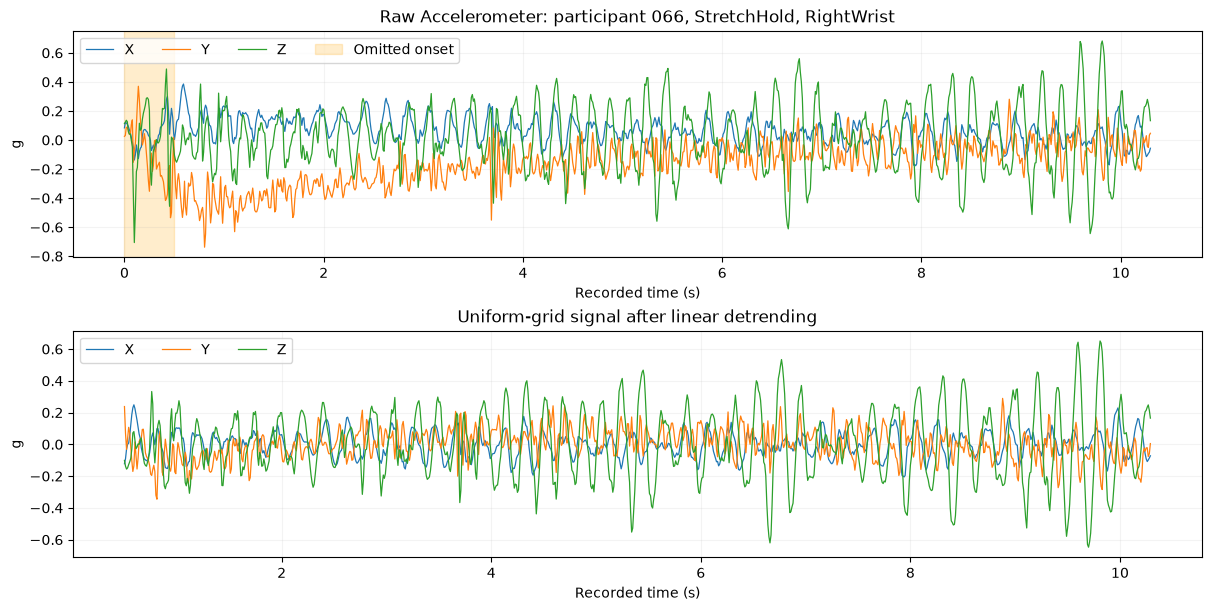

In [3]:
columns, unit = SENSORS[sensor]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), layout='constrained')
for j, name in enumerate('XYZ'):
    axes[0].plot(recording.time, recording.values[:, columns.start + j], label=name, lw=0.9)
    axes[1].plot(analysis.time, analysis.detrended_values[:, columns.start + j], label=name, lw=0.9)
axes[0].axvspan(recording.time[0], recording.time[0] + config.crop_seconds,
               color='orange', alpha=0.2, label='Omitted onset')
axes[0].set_title(f'Raw {sensor}: participant {participant_id}, {task}, {wrist}')
axes[1].set_title('Uniform-grid signal after linear detrending')
for ax in axes:
    ax.set_xlabel('Recorded time (s)'); ax.set_ylabel(unit)
    ax.legend(ncol=4); ax.grid(alpha=0.15)
plt.show()

## 3. Define the DFT, amplitude, and PSD precisely

For one real detrended axis $x_n$, apply the **periodic Hann window**

$$w_n=\tfrac12\left(1-\cos\frac{2\pi n}{N}\right),\quad n=0,\ldots,N-1.$$

The unnormalized DFT of the windowed data is

$$X_k=\sum_{n=0}^{N-1}w_nx_n\exp(-2\pi i kn/N),\qquad f_k=kf_s/N.$$

For the real FFT retain $k=0,\ldots,\lfloor N/2\rfloor$. Let $c_k=1$ at DC and, when $N$ is even, at $k=N/2$; let $c_k=2$ at the other retained bins. Then

$$A_k=\frac{c_k|X_k|}{\sum_n w_n},\qquad
P_k=\frac{c_k|X_k|^2}{f_s\sum_n w_n^2}.$$

$A_k$ has the original sensor unit. It recovers the amplitude of an appropriately isolated, bin-centered tone; it is not a universal exact amplitude estimator for arbitrary off-grid signals. $P_k$ has units of sensor-unit squared per Hz. With $\Delta f=f_s/N$,

$$\sum_k P_k\Delta f=\frac{\sum_nw_n^2x_n^2}{\sum_nw_n^2}.$$

This is the window-weighted mean square, not generally the unweighted sample variance. No zero padding is applied. Frequency-bin spacing is not equivalent to resolving power; the window broadens peaks.

**Welch PSD:** use segments of $L=400$ samples (4 seconds), periodic Hann weights, 200-sample overlap, a separate mean subtraction per segment, and arithmetic averaging of segment periodograms. Its grid spacing is $100/400=0.25$ Hz. Fewer segment samples give coarser frequency spacing; averaging reduces spectral variability.

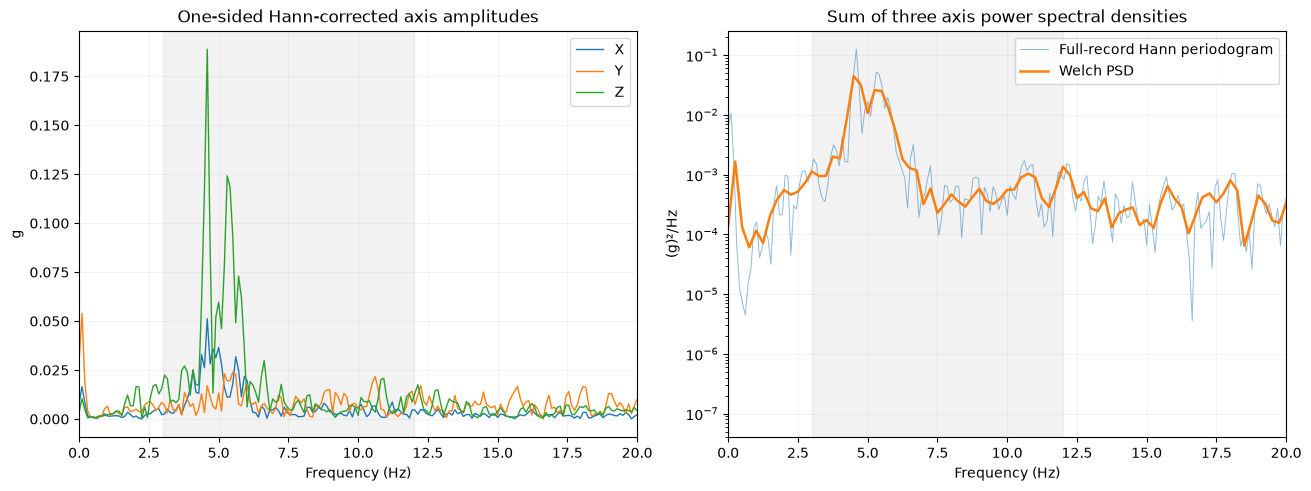

Full-record FFT bin spacing: 0.10204081632653061 Hz
Welch bin spacing: 0.25 Hz
Welch segments: 3


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout='constrained')
for j, name in enumerate('XYZ'):
    axes[0].plot(analysis.fft_frequency,
                 analysis.fft_amplitude[:, columns.start + j], label=name, lw=1)
f_fft, p_fft = vector_psd(analysis, sensor, method='fft')
f_welch, p_welch = vector_psd(analysis, sensor, method='welch')
axes[1].semilogy(f_fft, p_fft, alpha=0.5, lw=0.7, label='Full-record Hann periodogram')
axes[1].semilogy(f_welch, p_welch, lw=1.8, label='Welch PSD')
axes[0].set_title('One-sided Hann-corrected axis amplitudes')
axes[0].set_ylabel(unit)
axes[1].set_title('Sum of three axis power spectral densities')
axes[1].set_ylabel(f'({unit})²/Hz')
for ax in axes:
    ax.set_xlim(0, 20); ax.set_xlabel('Frequency (Hz)')
    ax.axvspan(3, 12, color='grey', alpha=0.1); ax.grid(alpha=0.15); ax.legend()
plt.show()
print('Full-record FFT bin spacing:', analysis.qc['fft_grid_spacing_hz'], 'Hz')
print('Welch bin spacing:', analysis.qc['welch_grid_spacing_hz'], 'Hz')
print('Welch segments:', analysis.qc['welch_segments'])

## 4. Define exploratory spectral features

Use the **sum of axis PSDs**, $S(f)=P_X(f)+P_Y(f)+P_Z(f)$. This is not the PSD of the nonlinear vector magnitude $\sqrt{x^2+y^2+z^2}$, which can introduce different frequency components.

Define the exploratory band $B=[3,12]$ Hz and reference band $R=[1,20]$ Hz. Include bins at both endpoints. The explicit bin-sum convention gives

$$Q_B=\Delta f\sum_{f_k\in B}S(f_k),\quad Q_R=\Delta f\sum_{f_k\in R}S(f_k),\quad r_B=Q_B/Q_R.$$

The peak is $f_{k_*}$ where $k_*$ is the **first** maximizing bin in $B$ (NumPy's argmax tie convention). It is undefined if band power is zero. A positive-power record gets a peak even if it lacks a clinically meaningful tremor. The 3–12 Hz band is a descriptive choice, not a diagnostic threshold.

In [5]:
features = spectral_features(f_welch, p_welch, config)
print(json.dumps(features, indent=2))
print('Power unit:', f'({unit})²')
checks = json.loads((OUTPUT / 'fourier_checks.json').read_text())
assert checks['passed']
print('Numerical check suite:', checks['check_count'], 'passed checks')
for check in checks['checks']:
    print('  -', check)

{
  "peak_frequency_hz": 4.5,
  "band_power": 0.04687645639611521,
  "reference_power": 0.05035599398722895,
  "band_power_fraction": 0.9309012231593282
}
Power unit: (g)²
Numerical check suite: 6 passed checks
  - Length 400: one-sided PSD equals SciPy periodogram and satisfies windowed Parseval identity.
  - Length 401: one-sided PSD equals SciPy periodogram and satisfies windowed Parseval identity.
  - Known 6 Hz sine: recovered 6 Hz peak, amplitude 2, and integrated power 2.
  - DC and even-length Nyquist amplitudes are not doubled.
  - Real ET recording: uniform 100 Hz grid, 0.5 s crop, no extrapolation, and 0.25 Hz Welch spacing.
  - Three-axis PSD sum and exploratory/reference band-power fraction are consistent.


## 5. Compare the full PD/ET cohort

The exported table contains **304 participants × 2 tasks × 2 sensors = 1,216 feature rows**. For each participant, task, and sensor, average the left and right axis-summed Welch PSDs **before** computing features. The underlying analysis checks **1,216 raw recordings** (304 × 2 tasks × 2 wrists).

Every participant contributes once per panel. Plotted bands are the interquartile range across participant PSDs, not confidence intervals. There is no random train/test split, significance test, or classifier evaluation. The two cohorts have 276 and 28 independent people; spectral distributions can overlap. Wrist averaging can dilute one-sided symptoms.

The cohort retains all published PD/ET assignments, including the eight PD-assigned records whose comments mention essential tremor. The demonstration examples were not selected to make the groups look separable.

Feature rows: 1216
Unique participants: 304
Rows per condition: {"Parkinson's": 1104, 'Essential Tremor': 112}


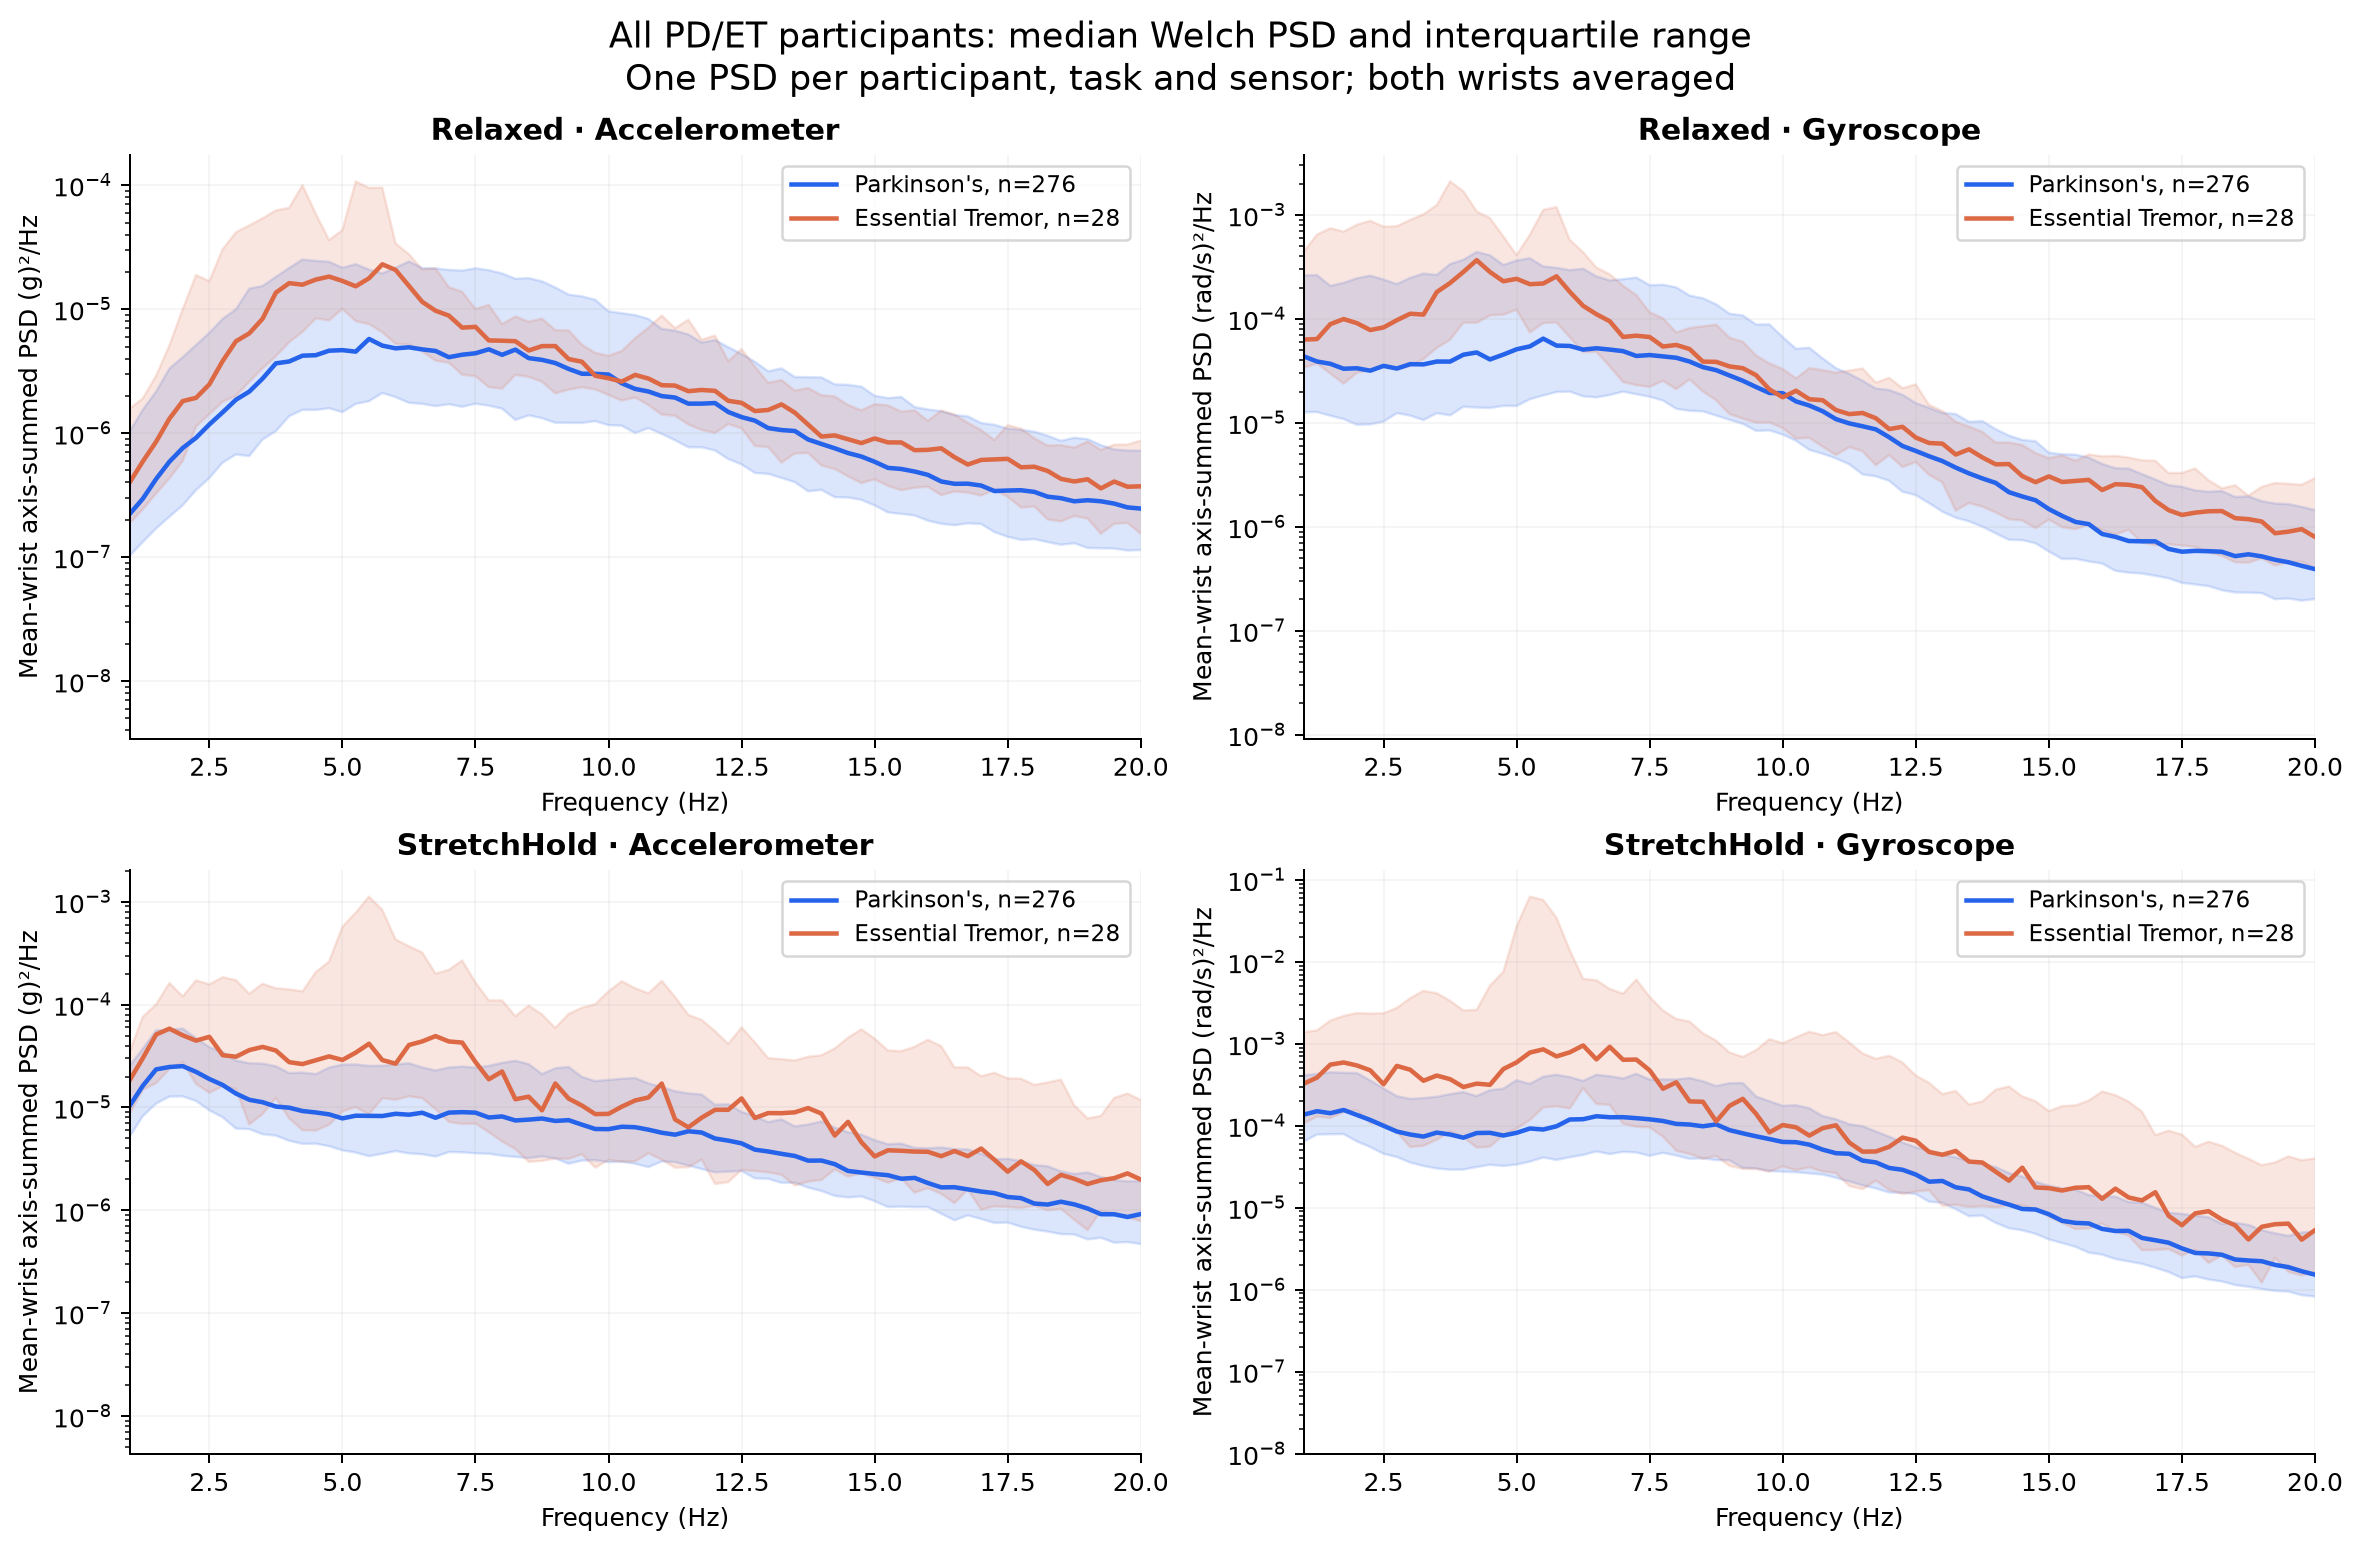

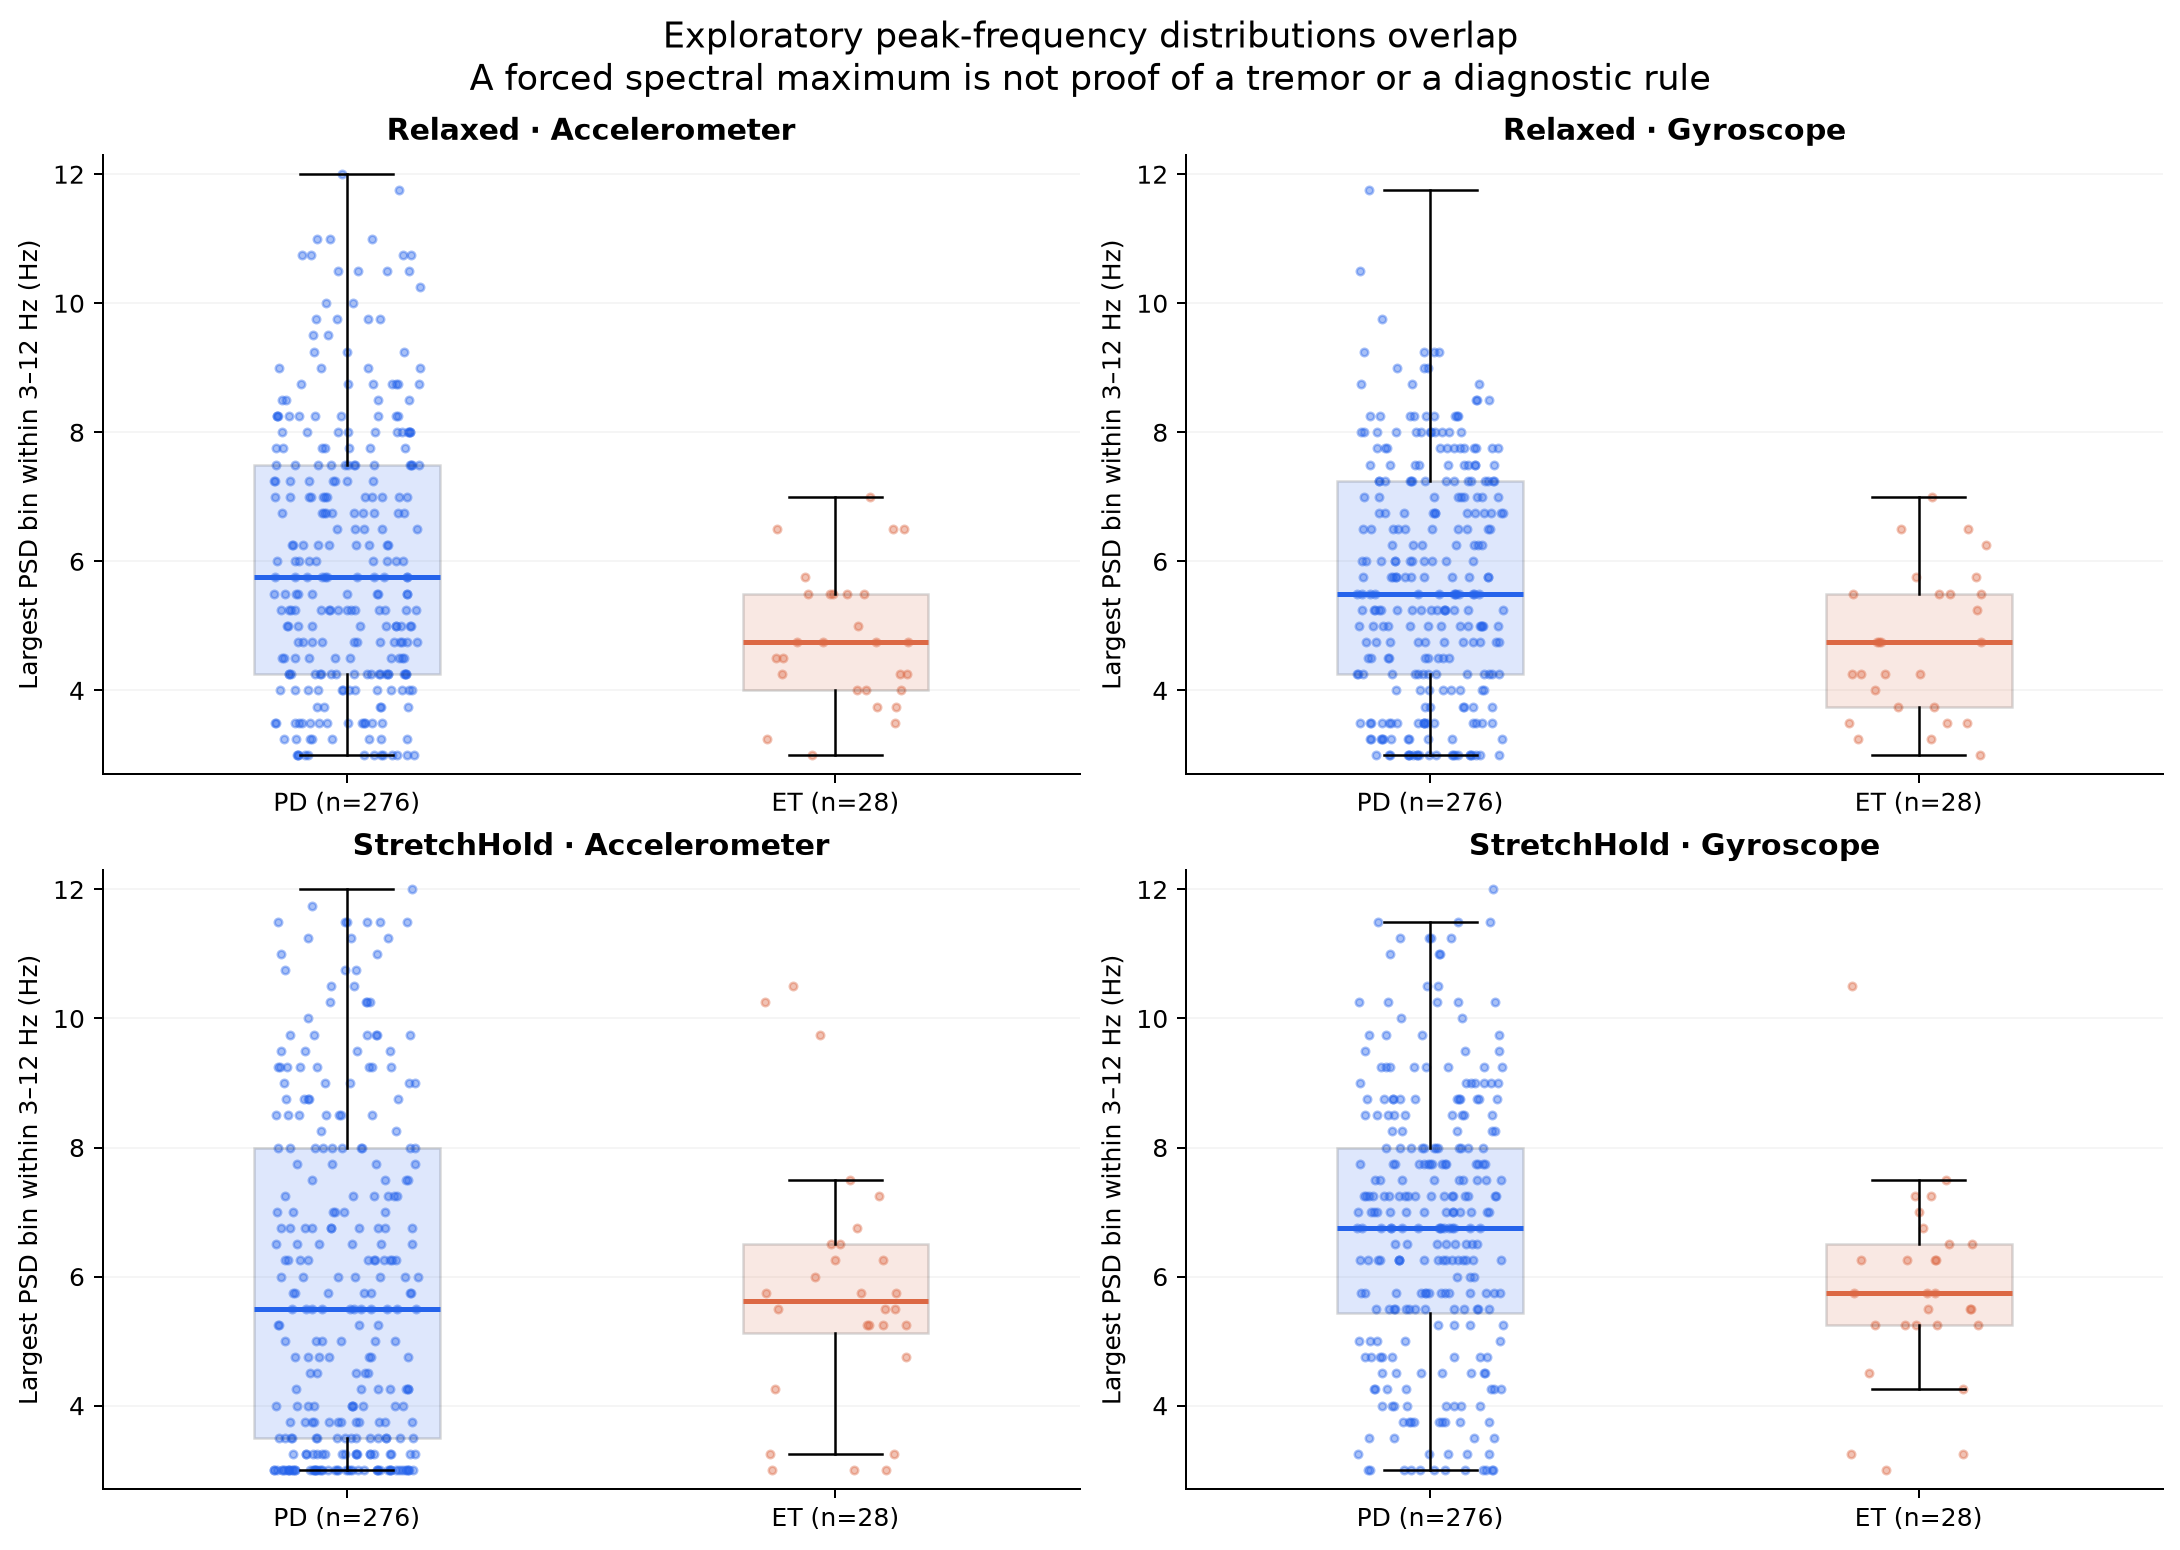

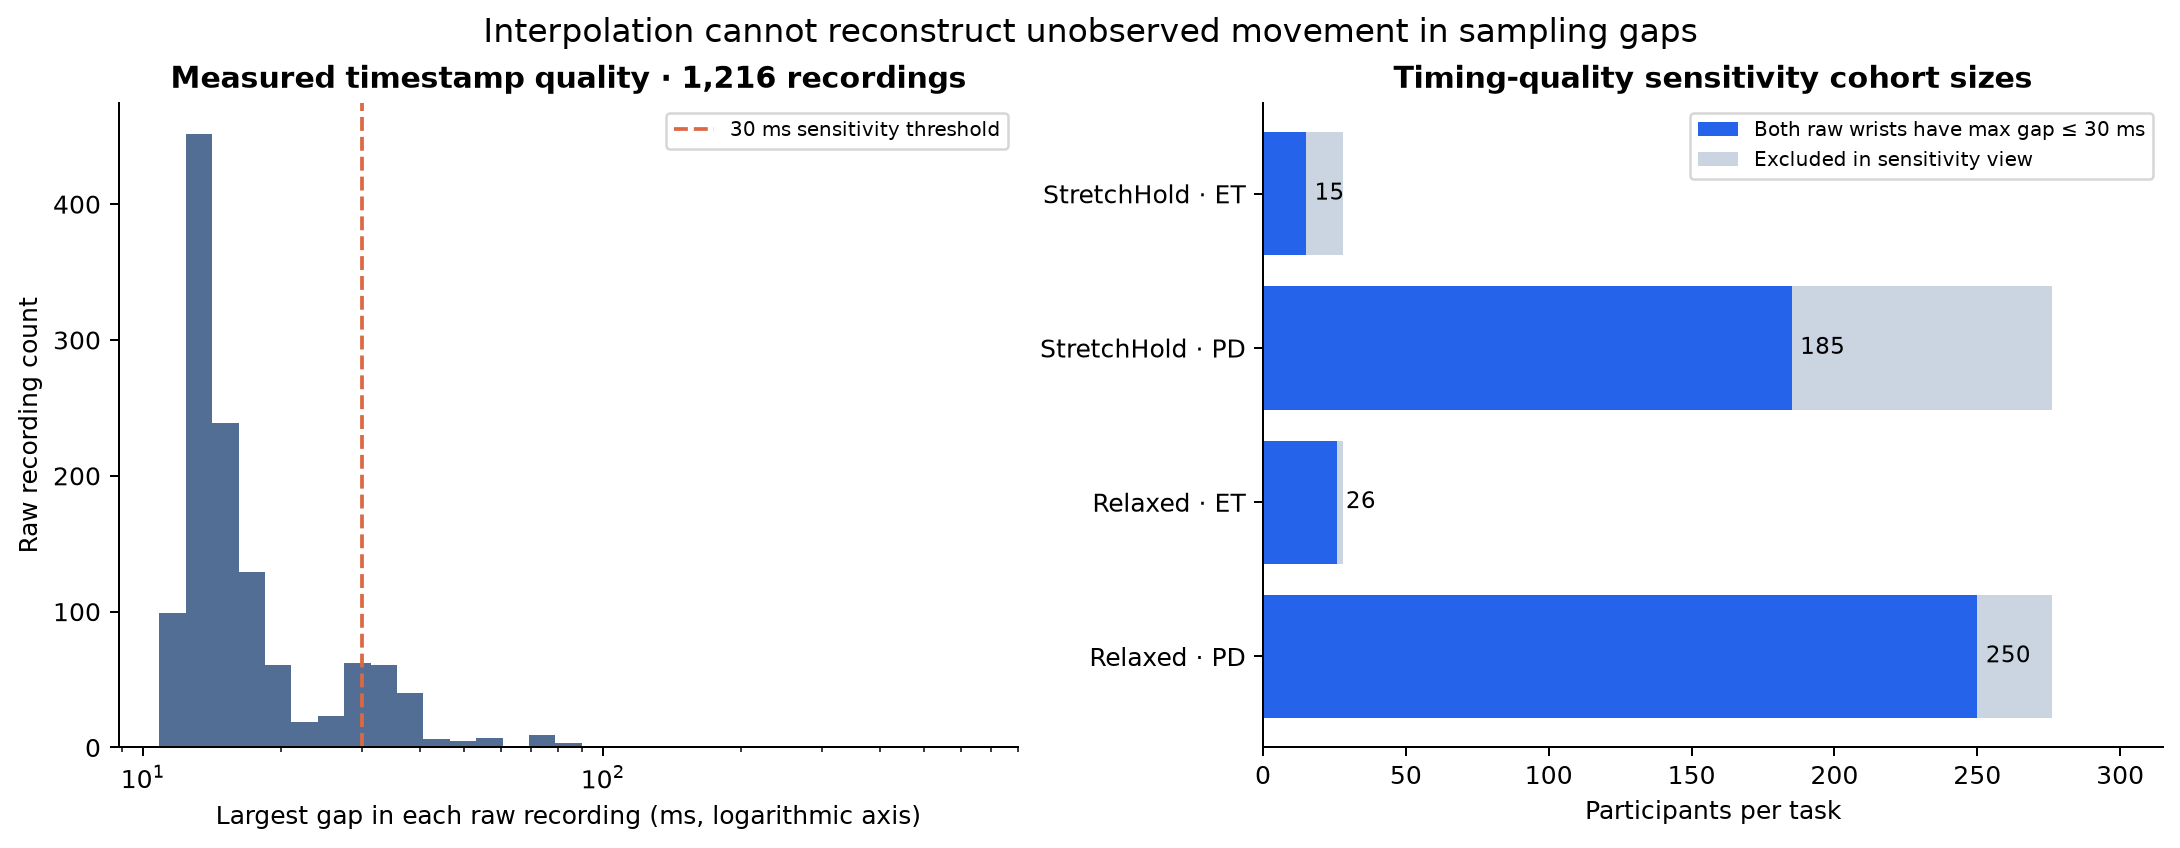

Sensitivity view: both raw wrist records must have maximum timestamp gap <= 30 ms.
This is a declared exploratory quality threshold, not a clinically validated cutoff.
Relaxed Parkinson's retained participants: 250
Relaxed Essential Tremor retained participants: 26
StretchHold Parkinson's retained participants: 185
StretchHold Essential Tremor retained participants: 15


In [6]:
with (OUTPUT / 'cohort_features.csv').open(newline='') as f:
    cohort = list(csv.DictReader(f))
print('Feature rows:', len(cohort))
print('Unique participants:', len({r['participant_id'] for r in cohort}))
print('Rows per condition:', dict(Counter(r['condition'] for r in cohort)))
display(Image(filename=str(OUTPUT / 'figures/cohort_spectra.png')))
display(Image(filename=str(OUTPUT / 'figures/cohort_features.png')))
display(Image(filename=str(OUTPUT / 'figures/timing_quality.png')))
print('Sensitivity view: both raw wrist records must have maximum timestamp gap <= 30 ms.')
print('This is a declared exploratory quality threshold, not a clinically validated cutoff.')
for t in ('Relaxed', 'StretchHold'):
    for c in ("Parkinson's", 'Essential Tremor'):
        selected = [r for r in cohort if r['task'] == t and r['condition'] == c
                    and r['sensor'] == 'Accelerometer' and r['passes_30ms_gap_sensitivity'] == 'True']
        print(t, c, 'retained participants:', len(selected))

## 6. Demonstration sequence and limitations

1. Start with the cohort counts and distinguish participant counts from recording counts.
2. Show raw XYZ channels and explain the first 0.5 seconds.
3. Show the synthetic Fourier teaching example, then the real axis amplitude spectrum.
4. Compare the full-record periodogram and Welch PSD, including their units and bin spacing.
5. Change task, wrist, or sensor in the offline explorer and describe what actually changes.
6. Show participant-level medians, interquartile ranges, and peak distributions. State the overlapping distributions and class imbalance.

The methods and quality checks concern this recorded dataset. Interpolation cannot repair missing motion, detrending does not remove all changing-orientation effects, and a largest spectral bin is not a clinical diagnosis. Any later classification experiment must keep all wrists, tasks, and windows of a participant together and fit preprocessing using training participants only.

References: [SciPy periodogram documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.periodogram.html), [SciPy Welch documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html), and the [official PADS protocol and usage notes](https://physionet.org/content/parkinsons-disease-smartwatch/1.0.0/).